# Efficient training of photonic quantum generative models — a reproduction

Gottlieb, Faraji, Mezher, Ventura, Mansfield, Salavrakos, arXiv:[2603.08793](https://arxiv.org/abs/2603.08793) (v2, 2026).
Original code: [merlinquantum/generative_classical_training](https://github.com/merlinquantum/generative_classical_training) (JAX, MIT).

This notebook is a guided argument, not a replot. It asks one question at a time, shows the
evidence, and says what that evidence does and does not establish. Everything that runs live
here is small (CPU, about 5 minutes in total). The paper-scale results (NVIDIA L4 GPUs, hundreds
of runs) are loaded from the curated files in `results/`, which were generated by scripts from
the raw run artifacts; their provenance is listed where they are used.

**Map of the notebook**

| § | Content | Live or stored |
|---|---|---|
| 1 | The claim and how it could fail | — |
| 2 | Data, splits, metrics, protocol | live (data loading) |
| 3 | The idea in equations | — |
| 4 | Known-answer sanity checks | live |
| 5 | Pipeline walkthrough | live |
| 6 | A small live version of Fig. 3a (5 seeds) | live |
| 7 | Headline paper-scale results | stored |
| 8 | Fair baseline comparison | stored |
| 9 | Controls and ablations | stored + live |
| 10 | Robustness and uncertainty | stored |
| 11 | Photonic assessment (MerLin) | live + stored |
| 12 | Conclusions | — |

In [1]:
import json
import sys
import time
import tempfile
from copy import deepcopy
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PAPER_DIR = Path.cwd()
if not (PAPER_DIR / "lib" / "runner.py").exists():
    PAPER_DIR = PAPER_DIR / "papers" / "photonic_MMD_generative"
REPO_ROOT = PAPER_DIR.parents[1]
for path in (REPO_ROOT, REPO_ROOT / "papers"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from runtime_lib.config import deep_update, load_config
from runtime_lib.dtypes import resolve_config_dtypes

from photonic_MMD_generative.lib import (
    circuits, data, estimator, exact, kernels, rbm_classical, runner,
)

jax.config.update("jax_enable_x64", True)
RESULTS = PAPER_DIR / "results"
DATA_ROOT = REPO_ROOT / "data"
pd.set_option("display.float_format", lambda v: f"{v:.3e}")

# One color per model family, used in every figure.
COLORS = {
    "QCBM": "#2a78d6", "B5 twin": "#eb6834", "paper RBM": "#1baf7a", "tuned RBM (B6)": "#0e6b4a",
    "B4 marginal": "#eda100", "uniform random": "#e87ba4", "test-to-test": "#8a8a85",
}
print("paper folder:", PAPER_DIR)
print("jax", jax.__version__, "| devices:", jax.devices())

paper folder: /Users/pemeriau/Codes/Reproduction/reproduced_papers/papers/photonic_MMD_generative
jax 0.11.2 | devices: [CpuDevice(id=0)]


## 1. Problem statement and the paper's claim

A **photonic quantum circuit Born machine (QCBM)** sends $n$ single photons into an $m$-mode
interferometer $U(\theta)$ and reads out which modes the photons land in. The output is a
bitstring-like occupation vector $x\in\mathbb{N}^m$ with $\sum_i x_i=n$. Sampling such a device is
*boson sampling*, believed hard classically. The paper's point is that **training** it can still
be classical: the MMD loss to a dataset can be written with observables whose expectations are
single $n\times n$ permanents, and those can be estimated without bias in polynomial time
(Gurvits). So one trains on a laptop and deploys on photons.

Claims examined here (IDs follow `LOG.md`):

| ID | Claim | Paper evidence |
|---|---|---|
| C1 | The MMD equals a Walsh-operator observable; each term is one permanent (Prop. 1–2) | proof |
| C2 | Training is efficient up to $m=256$, $n=16$, >100k parameters | §6, Fig. 2 |
| C4 | On boson-sampling (BS) data the QCBM **clearly outperforms** an RBM and a uniform random model | Fig. 3a |
| C5 | Butterfly and Haar ansätze beat Clements and 3-MZI | Fig. 3b |
| C6/C7 | Initialization matters little, except block initializations on block toy data | Fig. 3c–d, 4 |
| C8 | Kernel choice matters; on movies the polynomial kernel lets the QCBM **slightly overtake** the RBM | Fig. 3e–f |

**Falsifiable research question.** *Does a photonic QCBM trained with the classical
Gurvits/MMD estimator generate held-out data better (lower test MMD²) than competently trained
classical generative models, under one shared metric and protocol?*

**What would weaken the claim:**
- a classical model that is given the same information and a fair tuning budget matching or
  beating the QCBM on the same metric;
- the QCBM's margin disappearing when the metric is changed to one that every model can express;
- a classically samplable control (the same circuit with *distinguishable* photons) explaining
  most of the margin, which would mean bosonic interference is not what wins;
- the reported comparison mixing metrics between models.

## 2. Data, splits, metrics and evaluation protocol

**Datasets** (all under `data/photonic_MMD_generative/`, git-ignored; sources in `README.md`, *Data*):

| Dataset | m, n | Train / test | Status |
|---|---|---|---|
| Boson sampling (Fig. 2, 3a) | 256, 16 | 5000 / 5000 | regenerated with the paper's recipe and fixed seeds (authors' unitary not released) |
| Sushi top-10 (Fig. 3b) | 100, 10 | as in the code | original PrefLib data |
| Movies, Netflix (Fig. 3c–e) | 100, 10 | 10 000 / 10 000 | rebuilt with the authors' script, **unverified** |
| CMap bioinformatics (Fig. 3f) | 100, 10 | 7000 / 3000 | rebuilt, **unverified** |
| Pairwise sushi, mushroom (Fig. 4) | 100, 10 | as in the code | original data, toy construction |

Splits are fixed by seeded shuffles at preparation time; every model sees the same train split
and is scored on the same test split. **Nothing is selected on the test split** (the tuned RBM of
§8 selects on a validation split carved from train).

Let us load the Fig. 3a boson-sampling data and look at one property that matters a lot later.

In [2]:
def paper_config(name: str, **overrides) -> dict:
    # Resolved config: defaults.json + a named config + overrides, as the shared runtime does.
    cfg = deep_update(load_config(PAPER_DIR / "configs" / "defaults.json"), load_config(PAPER_DIR / "configs" / name))
    cfg = resolve_config_dtypes(deep_update(cfg, overrides))
    cfg["data_root"] = str(DATA_ROOT)
    return cfg

cfg_bs = paper_config("fig3a_bs_original.json")
bs = data.load_dataset(cfg_bs)          # prepared cache; built with Perceval if absent (slow)
X_train, X_test = bs["train"], bs["test"]
collision = (X_test.max(axis=1) > 1).mean()
print("dataset id:", bs["manifest"]["dataset_id"])
print("train", X_train.shape, "test", X_test.shape, "| photons per sample:", set(X_test.sum(axis=1)))
print(f"fraction of test samples with >= 2 photons in some mode: {collision:.3f}")
print("distinct occupied modes per sample (binarized weight): mean", np.minimum(X_test, 1).sum(axis=1).mean().round(2))

dataset id: boson_sampling_m256_n16_dc2ef771c2
train (5000, 256) test (5000, 256) | photons per sample: {np.int64(16)}
fraction of test samples with >= 2 photons in some mode: 0.608
distinct occupied modes per sample (binarized weight): mean 15.11


**Observation.** About 60% of the boson-sampling samples have a *collision* (two or more photons
in one mode). The paper's theory (Prop. 1) assumes collision-free data, which holds only when
$m \gg n^2$; here $m = n^2 = 256$.

**Why it matters for the protocol.** A model that outputs bits (an RBM) cannot produce a count of 2.
A Gaussian kernel on raw counts then penalizes it for its *representation*, not for what it
learned. We therefore score every model on three representations of the same samples:

| Metric | Definition | Who can express it |
|---|---|---|
| `gaussian_mmd_raw` | unbiased MMD² with $k(x,y)=e^{-\lVert x-y\rVert^2/2\sigma^2}$ on raw counts | count-valued models only (QCBM, B5) |
| `gaussian_mmd_binarized` | same on $\min(x,1)$ | **every model** → primary metric for the fair comparison |
| `walsh_mmd` | MMD² on parity features $(-1)^{k\cdot x}$, $k\sim P_\sigma$ (what the QCBM trains on) | every model |

All are unbiased U-statistics with 2000 model samples against the 5000 test samples. Lower is
better; the test-to-test value (two halves of the test set) is the noise floor (≈ 0).
**Protocol (Phase 5, frozen before the new runs):** 5 seeds; mean and standard deviation;
a difference counts only if $|\Delta| > 2\,\mathrm{SE}$, with $\mathrm{SE}=\sqrt{s_1^2/n_1+s_2^2/n_2}$.

## 3. The idea in equations

For two distributions $p,q$ on collision-free bitstrings, the Gaussian-kernel MMD can be written
in the **Walsh (parity) basis** (Prop. 1):

$$
\mathrm{MMD}^2_\sigma(p,q)=\mathbb{E}_{k\sim P_\sigma}\Big[\big(\langle W_k\rangle_p-\langle W_k\rangle_q\big)^2\Big],
\qquad W_k=\mathrm{diag}\big((-1)^{k\cdot x}\big),
\qquad P_\sigma(k)=\prod_i p_\sigma^{k_i}(1-p_\sigma)^{1-k_i},\; p_\sigma=\tfrac{1-e^{-1/(2\sigma^2)}}{2}.
$$

The data term $\langle W_k\rangle_q$ is an average over the dataset. The model term is a photonic
observable: $W_k$ acts on each mode as a phase $\pm1$, so

$$
\langle W_k\rangle_{\text{model}}=\mathrm{Per}\big(A_k\big),\qquad A_k=U_S^\dagger\,\mathrm{diag}(1-2k)\,U_S\in\mathbb{C}^{n\times n},
$$

where $U_S$ are the $n$ columns of $U$ that receive a photon. **Gurvits/Glynn**: for random signs
$z\in\{\pm1\}^n$, $\mathrm{Per}(A)=\mathbb{E}_z\big[\prod_i z_i \prod_j (Az)_j\big]$, which needs only $O(n^2)$ per
sample. Drawing $|K|$ operators and $|Z|$ sign vectors per step gives an unbiased loss estimate
(Eq. 15) whose gradient comes from autodiff. Other kernels only change $P(k)$ (Prop. 2, App. A).

Three facts to check before trusting any result: the identity itself, the estimator's
unbiasedness, and that the circuits we train are actually unitary.

## 4. Known-answer sanity checks (live)

**4a — Prop. 1.** On a small space (m = 6, n = 2) compute the MMD between two random
collision-free distributions directly with the Gaussian kernel and through the Walsh form.

In [3]:
rng = np.random.default_rng(1)
M_SMALL, N_SMALL, SIGMA_SMALL = 6, 2, 1.0
support = [s for s in exact.fock_states(M_SMALL, N_SMALL) if max(s) <= 1]
p_w, q_w = rng.random(len(support)), rng.random(len(support))
p = dict(zip(support, p_w / p_w.sum()))
q = dict(zip(support, q_w / q_w.sum()))
direct = exact.kernel_mmd(p, q, exact.gaussian_kernel(SIGMA_SMALL))
walsh = exact.walsh_mmd(p, q, exact.gaussian_operator_probability(SIGMA_SMALL))
print(f"direct Gaussian MMD^2 = {direct:.12e}\nWalsh form            = {walsh:.12e}\nrelative difference   = {abs(direct - walsh) / direct:.1e}")

direct Gaussian MMD^2 = 3.380766316695e-02
Walsh form            = 3.380766316695e-02
relative difference   = 2.1e-16


**4b — the estimator is unbiased.** Take a random Haar interferometer at m = 6, n = 2, compute
its exact output distribution with permanents, and compare the *exact expected value* of the
paper's stochastic loss (given the data sample) with the mean of 30 independent estimates.

In [4]:
import itertools

INPUT_MODES_SMALL = [1, 3]
unitary_fn_small = circuits.make_unitary_fn(M_SMALL, "haar")
params_small = jax.random.normal(jax.random.PRNGKey(3), (2 * M_SMALL * M_SMALL,))
U_small = np.asarray(unitary_fn_small(params_small))
model_dist = exact.output_distribution(U_small, INPUT_MODES_SMALL)
rows = rng.choice(len(support), size=400, p=p_w / p_w.sum())
X_small = np.array([support[i] for i in rows], dtype=float)

def expected_loss(distribution, X, sigma):
    # E_{K,Z}[estimator | X] = sum_k P(k) [G_k^2 - 2 G_k T_k + (N T_k^2 - 1)/(N - 1)]
    prob, N_ = exact.gaussian_operator_probability(sigma), len(X)
    total = 0.0
    for bits in itertools.product((0, 1), repeat=M_SMALL):
        k = np.array(bits)
        G = sum(pr * (-1) ** int(k @ np.array(s)) for s, pr in distribution.items())
        T = np.mean((-1.0) ** (X @ k))
        total += prob(k) * (G * G - 2 * G * T + (N_ * T * T - 1) / (N_ - 1))
    return total

target = expected_loss(model_dist, X_small, SIGMA_SMALL)
sampler_small = kernels.make_operator_sampler({"type": "gaussian", "sigma": SIGMA_SMALL}, M_SMALL, N_SMALL)
loss_small = estimator.make_mmd_loss(unitary_fn_small, INPUT_MODES_SMALL, sampler_small, 3000, 3000, "indistinguishable")
estimates = np.array([float(loss_small(params_small, jax.random.PRNGKey(i), jnp.asarray(X_small))) for i in range(30)])
se = estimates.std(ddof=1) / np.sqrt(len(estimates))
print(f"exact expectation {target:.6e} | mean of 30 estimates {estimates.mean():.6e} ± {se:.1e} (SE) | z = {(estimates.mean() - target) / se:+.2f}")

exact expectation 1.017377e-01 | mean of 30 estimates 1.018088e-01 ± 4.0e-04 (SE) | z = +0.18


**4c — are the circuits unitary?** The paper's butterfly mesh pairs mode $i$ with $i+2^l$. At
$m = 100$ (not a power of two) some pairs point outside the circuit. Check $\lVert U^\dagger U-I\rVert$ at a
random initialization for every ansatz used in Fig. 3b.

In [5]:
M_BIG = 100
rows_u = []
for ansatz, variant in [("haar", "reference"), ("clements", "reference"), ("mzi3", "reference"),
                        ("butterfly", "reference"), ("butterfly", "corrected")]:
    fn = circuits.make_unitary_fn(M_BIG, ansatz, variant)
    theta = jax.random.uniform(jax.random.PRNGKey(0), (circuits.num_parameters(M_BIG, ansatz),), maxval=2 * np.pi)
    U = fn(theta)
    singular = np.linalg.svd(np.asarray(U), compute_uv=False)
    rows_u.append({"ansatz": f"{ansatz} ({variant})" if ansatz == "butterfly" else ansatz,
                   "parameters": circuits.num_parameters(M_BIG, ansatz),
                   "unitarity error": circuits.unitarity_error(U),
                   "singular values": f"{singular.min():.2f} – {singular.max():.2f}"})
pd.DataFrame(rows_u)

,ansatz,parameters,unitarity error,singular values
0,haar,20000,1.110e-15,1.00 – 1.00
1,clements,10000,2.220e-15,1.00 – 1.00
2,mzi3,10000,1.887e-14,1.00 – 1.00
3,butterfly (reference),10000,1.416e+00,0.00 – 3.61
4,butterfly (corrected),10000,1.332e-15,1.00 – 1.00


**Observation.** (4a) The Walsh form equals the Gaussian MMD to machine precision. (4b) The
estimator's mean matches the exact expectation within its standard error. (4c) Haar, Clements and
3-MZI are unitary to ~1e-15; the **original butterfly is not unitary at m = 100** (singular values
spread far from 1), while the corrected butterfly is.

**Inference.** The estimator and our implementation are trustworthy (C1 supported). The original
butterfly is not a physical interferometer at m = 100: its trained "models" cannot be deployed, and
any result about it reflects the bug, not optics.

**Remaining uncertainty.** These are small-size checks; at paper scale correctness rests on the
same code paths (tests in `tests/test_estimator.py`, `tests/test_circuits_kernels.py`).

**Claim impact.** C1 reproduced. Part of C6 ("butterfly is more sensitive to initialization") is
explained by the non-unitary mesh (§9).

## 5. Pipeline walkthrough

One run = `lib/runner.py::train_and_evaluate(cfg, run_dir)`:

```text
data.load_dataset ──► initialization (near-identity: U ≈ I + small perturbation)
        │
        ▼
estimator.make_mmd_loss (|K| Walsh operators, |Z| Glynn signs, fresh each step)
        │  autodiff + Adam (lr 0.01), ≤ 2000 steps, stop when the 200-step window mean stops decreasing
        ▼
trained U ──► sample 2000 outputs (Perceval boson sampler; B5: distinguishable photons)
        │
        ▼
sample-based MMD² vs test split for the model and every baseline (same K operators)
```

All scientifically important settings are in the config. Here is the resolved Fig. 3a config:

In [6]:
show = {k: cfg_bs[k] for k in ("dataset", "model", "kernel", "init", "training", "evaluation")}
print(json.dumps(show, indent=1)[:2500])
print("\nQCBM parameters (Haar, 2 m^2):", circuits.num_parameters(256, "haar"))
print("paper RBM parameters (m*64 + m + 64):", rbm_classical.num_parameters(256, 64))
print("iso-parameter RBM (512 hidden):", rbm_classical.num_parameters(256, 512))

{
 "dataset": {
  "name": "boson_sampling",
  "m": 256,
  "n": 16,
  "n_train": 5000,
  "n_test": 5000,
  "seed": 0,
  "input_state": "middle_compact",
  "unitary_seed": 2603,
  "sample_seed": 8793
 },
 "model": {
  "ansatz": "haar",
  "butterfly_variant": "reference",
  "input_state": "middle_alternating",
  "photon_model": "indistinguishable",
  "backend": "jax"
 },
 "kernel": {
  "type": "gaussian",
  "sigma": 3.0
 },
 "init": {
  "strategy": "identity",
  "perturbation": 0.01
 },
 "training": {
  "steps": 2000,
  "learning_rate": 0.01,
  "n_operators": 2000,
  "n_gurvits": 5000,
  "convergence_interval": 200,
  "log_every": 1
 },
 "evaluation": {
  "n_operators": 2000,
  "n_gurvits": 5000,
  "sample_metrics": true,
  "num_model_samples": 2000,
  "baselines": [
   "random",
   "marginal",
   "rbm",
   "test_to_test"
  ],
  "rbm": {
   "n_components": 64,
   "learning_rate": 0.01,
   "batch_size": 64,
   "n_iter": 2000,
   "mmd_samples": 1000,
   "gibbs_steps": 10,
   "score_sigma": 

## 6. A small live experiment: Fig. 3a in miniature

The paper-scale Fig. 3a (m = 256, n = 16) takes about 90 s per QCBM run on a GPU plus ~50 min of
RBM tuning per seed, too slow for a notebook. The same comparison at **m = 12, n = 3** (boson-sampling
data from a different random interferometer, same recipe) runs on a CPU in a few minutes.

**Reduced settings (label: *partial, live smoke-scale*):** $|K|=|Z|=500$ instead of 2000/5000,
tuned RBM trained 500 epochs instead of 2000, σ = 1. Steps (≤ 2000), the 200-step stopping rule,
estimator, initialization, baselines, metrics and seeds 0–4 are as in the paper-scale pipeline.

Models, each scored on the same test split with the same metric code:
- **QCBM**: Haar interferometer, indistinguishable photons.
- **B5 twin**: the same circuit and training with distinguishable photons. Classically samplable;
  it isolates what bosonic interference adds.
- **paper RBM**: the paper's RBM (64 hidden, 10 Gibbs steps, trained on raw counts).
- **tuned RBM (B6)**: trained on binarized data; hidden {8, 21 (iso-parameter at m=12), 64} × lr {1e-2, 1e-3},
  Gibbs {10, 100, 1000}; selected on a validation split of the training set, refit on all training data.
- **B4 marginal**: samples n distinct modes from the training mode frequencies (first-order statistics only).
- **uniform random** and **test-to-test** (noise floor).

In [7]:
LIVE_SEEDS = [0, 1, 2, 3, 4]
LIVE_OVERRIDES = {
    "dataset": {"name": "boson_sampling", "m": 12, "n": 3, "n_train": 5000, "n_test": 5000,
                "input_state": "middle_compact", "unitary_seed": 2615, "sample_seed": 8805},
    "kernel": {"type": "gaussian", "sigma": 1.0},
    "training": {"steps": 2000, "n_operators": 500, "n_gurvits": 500, "convergence_interval": 200, "log_every": 50},
    "evaluation": {"n_operators": 2000, "n_gurvits": 2000, "num_model_samples": 2000,
                   "baselines": ["random", "marginal", "rbm", "test_to_test"], "rbm": {"score_sigma": 1.0}},
}
B6_LIVE = {"sigmas": [1.0], "hidden_units": [8, 21, 64], "learning_rates": [0.01, 0.001],
           "gibbs_steps": [10, 100, 1000], "batch_size": 64, "n_iter": 500,
           "validation_size": 1000, "split_seed": 20261015, "num_samples": 2000}
VARIANTS = {
    "qcbm": {},
    "b5": {"model": {"photon_model": "distinguishable"}, "evaluation": {"baselines": []}},
    "b6": {"model": {"backend": "rbm_tuned"}, "tuning": B6_LIVE},
}

live_dir = Path(tempfile.mkdtemp(prefix="qcbm_live_"))
live_metrics, live_seconds = {}, {}
start_all = time.perf_counter()
for seed in LIVE_SEEDS:
    for name, extra in VARIANTS.items():
        cfg = deep_update(paper_config("defaults.json", **LIVE_OVERRIDES), deepcopy(extra))
        cfg["data_root"], cfg["seed"] = str(DATA_ROOT), seed
        run_dir = live_dir / f"{name}_seed{seed}"
        run_dir.mkdir()
        t0 = time.perf_counter()
        runner.train_and_evaluate(cfg, run_dir)
        live_seconds[(name, seed)] = time.perf_counter() - t0
        status = json.loads((run_dir / "run_status.json").read_text())["status"]
        assert status == "COMPLETED", (name, seed, status)
        live_metrics[(name, seed)] = json.loads((run_dir / "metrics.json").read_text())
print(f"{len(live_metrics)} live runs completed in {time.perf_counter() - start_all:.0f} s")

15 live runs completed in 226 s


In [8]:
def live_rows():
    for seed in LIVE_SEEDS:
        q, b5, b6 = (live_metrics[(k, seed)] for k in ("qcbm", "b5", "b6"))
        sources = {
            "QCBM": q["sample_metrics"]["model"], "B5 twin": b5["sample_metrics"]["model"],
            "paper RBM": q["sample_metrics"]["rbm"], "tuned RBM (B6)": b6["sample_metrics_by_sigma"]["1.0"]["rbm_tuned"],
            "B4 marginal": q["sample_metrics"]["marginal"], "uniform random": q["sample_metrics"]["random"],
        }
        for model, entry in sources.items():
            for metric in ("gaussian_mmd_binarized", "walsh_mmd", "gaussian_mmd_raw"):
                yield {"seed": seed, "model": model, "metric": metric, "value": entry[metric]}
        yield {"seed": seed, "model": "test-to-test", "metric": "walsh_mmd", "value": q["sample_metrics"]["test_to_test"]["walsh_mmd"]}

live = pd.DataFrame(live_rows())
live_summary = live.pivot_table(index="model", columns="metric", values="value", aggfunc=["mean", "std"])
order = ["QCBM", "B5 twin", "tuned RBM (B6)", "paper RBM", "B4 marginal", "uniform random", "test-to-test"]
live_summary.loc[order]

mean                              \
metric         gaussian_mmd_binarized gaussian_mmd_raw  walsh_mmd   
model                                                               
QCBM                        7.798e-03        1.129e-02  6.628e-04   
B5 twin                     2.910e-03        4.428e-03  3.362e-03   
tuned RBM (B6)              1.194e-02        5.236e-02  2.145e-03   
paper RBM                   4.498e-02        4.370e-02  7.442e-02   
B4 marginal                 7.966e-03        1.568e-02  2.938e-02   
uniform random              2.453e-02        2.606e-02  3.598e-02   
test-to-test                      NaN              NaN -1.419e-04   

                                  std                             
metric         gaussian_mmd_binarized gaussian_mmd_raw walsh_mmd  
model                                                             
QCBM                        6.662e-03        9.607e-03 4.857e-04  
B5 twin                     2.927e-04        4.732e-04 5.039e-04  
tuned RBM (B6)              7.604e-04        1.582e-03 4.811e-04  
paper RBM                   2.479e-03        5.165e-03 5.408e-03  
B4 marginal                 2.909e-04        3.608e-04 1.166e-03  
uniform random              8.441e-04        6.726e-04 9.944e-04  
test-to-test                      NaN              NaN 9.740e-05

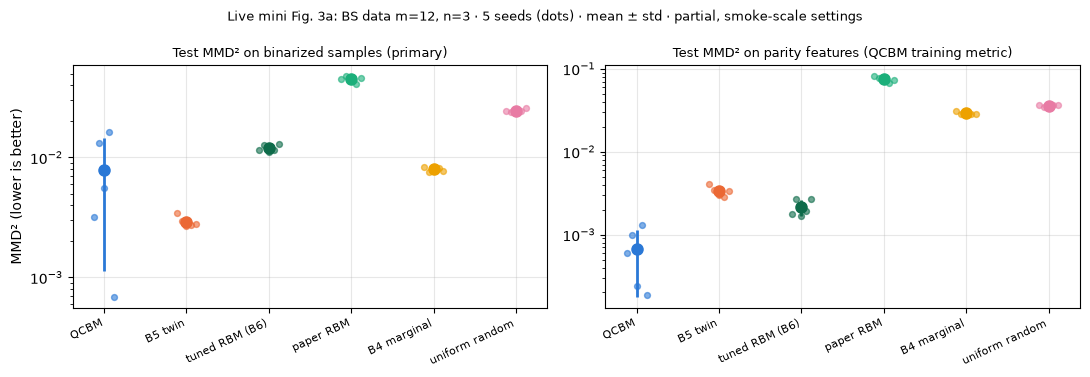

,baseline,Δ (QCBM − baseline),2 SE,decision
0,B5 twin,4.888e-03,5.964e-03,not separated
1,tuned RBM (B6),-4.140e-03,5.997e-03,not separated
2,paper RBM,-3.718e-02,6.357e-03,QCBM better
3,B4 marginal,-1.685e-04,5.964e-03,not separated
4,uniform random,-1.674e-02,6.006e-03,QCBM better


In [9]:
def strip_plot(ax, frame, models, metric, title):
    for i, model in enumerate(models):
        values = frame[(frame.model == model) & (frame.metric == metric)].value.to_numpy()
        ax.scatter(np.full(values.size, i) + np.linspace(-0.12, 0.12, values.size), values, s=18,
                   color=COLORS[model], alpha=0.6, zorder=2)
        ax.errorbar(i, values.mean(), yerr=values.std(ddof=1), fmt="o", color=COLORS[model],
                    markersize=8, elinewidth=2, zorder=3)
    ax.set_xticks(range(len(models)), models, rotation=25, ha="right", fontsize=8)
    ax.set_yscale("log"); ax.set_title(title, fontsize=9); ax.grid(alpha=0.3)

models_live = ["QCBM", "B5 twin", "tuned RBM (B6)", "paper RBM", "B4 marginal", "uniform random"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
strip_plot(axes[0], live, models_live, "gaussian_mmd_binarized", "Test MMD² on binarized samples (primary)")
strip_plot(axes[1], live, models_live, "walsh_mmd", "Test MMD² on parity features (QCBM training metric)")
axes[0].set_ylabel("MMD² (lower is better)")
fig.suptitle("Live mini Fig. 3a: BS data m=12, n=3 · 5 seeds (dots) · mean ± std · partial, smoke-scale settings", fontsize=9)
plt.tight_layout(); plt.show()

def decide(a, b):
    # Frozen Phase 5 rule: separated only if |Δ| > 2 SE.
    a, b = np.asarray(a), np.asarray(b)
    delta = a.mean() - b.mean()
    two_se = 2 * np.sqrt(a.var(ddof=1) / a.size + b.var(ddof=1) / b.size)
    return delta, two_se, ("QCBM better" if delta < -two_se else "baseline better" if delta > two_se else "not separated")

primary = live[live.metric == "gaussian_mmd_binarized"]
qv = primary[primary.model == "QCBM"].value
pd.DataFrame([
    dict(zip(("baseline", "Δ (QCBM − baseline)", "2 SE", "decision"), (m, *decide(qv, primary[primary.model == m].value))))
    for m in models_live[1:]
])

In [10]:
per_seed = pd.DataFrame([
    {"seed": seed,
     "QCBM steps run": live_metrics[("qcbm", seed)]["training"]["steps_run"],
     "QCBM paper estimator": live_metrics[("qcbm", seed)]["test_mmd_estimator"],
     "B5 paper estimator": live_metrics[("b5", seed)]["test_mmd_estimator"],
     "QCBM parity (walsh)": live_metrics[("qcbm", seed)]["sample_metrics"]["model"]["walsh_mmd"],
     "B5 parity (walsh)": live_metrics[("b5", seed)]["sample_metrics"]["model"]["walsh_mmd"],
     "QCBM binarized": live_metrics[("qcbm", seed)]["sample_metrics"]["model"]["gaussian_mmd_binarized"],
     "B5 binarized": live_metrics[("b5", seed)]["sample_metrics"]["model"]["gaussian_mmd_binarized"],
     "B4 binarized": live_metrics[("qcbm", seed)]["sample_metrics"]["marginal"]["gaussian_mmd_binarized"]}
    for seed in LIVE_SEEDS]).set_index("seed")
b5_best = per_seed["B5 paper estimator"].min()
print("QCBM seeds below every B5 seed — paper estimator:", int((per_seed["QCBM paper estimator"] < b5_best).sum()), "/ 5;",
      "parity:", int((per_seed["QCBM parity (walsh)"] < per_seed["B5 parity (walsh)"].min()).sum()), "/ 5;",
      "binarized:", int((per_seed["QCBM binarized"] < per_seed["B5 binarized"].min()).sum()), "/ 5")
per_seed

QCBM seeds below every B5 seed — paper estimator: 5 / 5; parity: 5 / 5; binarized: 1 / 5


,QCBM steps run,QCBM paper estimator,B5 paper estimator,QCBM parity (walsh),B5 parity (walsh),QCBM binarized,B5 binarized,B4 binarized
seed,,,,,,,,
0,1177,3.644e-04,3.233e-03,5.948e-04,4.128e-03,3.188e-03,3.409e-03,8.269e-03
1,954,1.832e-03,3.245e-03,9.818e-04,3.481e-03,1.332e-02,2.930e-03,7.629e-03
2,1162,3.435e-04,3.330e-03,2.372e-04,3.011e-03,5.608e-03,2.699e-03,8.046e-03
3,1517,1.250e-03,3.216e-03,1.316e-03,2.822e-03,1.619e-02,2.735e-03,8.195e-03
4,1201,2.368e-04,3.204e-03,1.840e-04,3.367e-03,6.865e-04,2.775e-03,7.693e-03


**Observation.** The QCBM seeds split in two. With the paper's own estimator (deterministic for a
given seed) every QCBM seed beats every B5 seed, but the QCBM seeds spread over about 8× while the
B5 seeds agree within a few percent. On the binarized metric the picture flips for the weaker
seeds: several end worse than the distinguishable twin B5, and the worst two worse than the
marginal sampler B4 (the printed counts above give the exact tallies for this execution).

Sample-based values for single seeds move by up to about 20% between executions, because
Perceval's `Clifford2017Backend` cannot be seeded and 2000 samples at m = 12 leave visible noise;
the split itself comes from training, which is deterministic. Under the frozen 2-SE rule the QCBM is therefore **not
separated** from B5, B4 or the tuned RBM at this scale, and is better only than the paper RBM and
the random model.

Is this an artefact of the stopping rule (runs halted too early)? Rerun the poor seeds with twice
the steps and **no early stopping**. (The seeds are picked by their test score: this is a
diagnostic of training, not a selection of any reported result.)

In [11]:
b5_worst = max(live_metrics[("b5", s)]["sample_metrics"]["model"]["gaussian_mmd_binarized"] for s in LIVE_SEEDS)
stuck = [s for s in LIVE_SEEDS if live_metrics[("qcbm", s)]["sample_metrics"]["model"]["gaussian_mmd_binarized"] > b5_worst]
rerun = []
for seed in stuck:
    cfg = paper_config("defaults.json", **LIVE_OVERRIDES)
    cfg = deep_update(cfg, {"training": {"steps": 4000, "convergence_interval": None}, "evaluation": {"baselines": []}})
    cfg["data_root"], cfg["seed"] = str(DATA_ROOT), seed
    run_dir = live_dir / f"qcbm_nostop_seed{seed}"
    run_dir.mkdir()
    runner.train_and_evaluate(cfg, run_dir)
    m = json.loads((run_dir / "metrics.json").read_text())
    rerun.append({"seed": seed, "steps run": m["training"]["steps_run"],
                  "estimator before": per_seed.loc[seed, "QCBM paper estimator"], "estimator after": m["test_mmd_estimator"],
                  "parity before": per_seed.loc[seed, "QCBM parity (walsh)"], "parity after": m["sample_metrics"]["model"]["walsh_mmd"],
                  "binarized before": per_seed.loc[seed, "QCBM binarized"], "binarized after": m["sample_metrics"]["model"]["gaussian_mmd_binarized"]})
print("seeds worse than every B5 seed on the binarized metric:", stuck)
pd.DataFrame(rerun).set_index("seed") if rerun else "no stuck seeds in this run"

seeds worse than every B5 seed on the binarized metric: [1, 2, 3]


,steps run,estimator before,estimator after,parity before,parity after,binarized before,binarized after
seed,,,,,,,
1,4000,1.832e-03,1.431e-03,9.818e-04,1.169e-03,1.332e-02,1.694e-02
2,4000,3.435e-04,2.095e-04,2.372e-04,4.024e-04,5.608e-03,3.316e-03
3,4000,1.250e-03,1.157e-03,1.316e-03,1.253e-03,1.619e-02,1.700e-02


**Observation.** With twice the steps and no early stopping, the paper's estimator for the two worst
seeds (1 and 3) improves only modestly (by 7–22%) and stays 5–6× above the best seeds, and their
binarized MMD² does not improve. The weak seeds sit in a **poor local optimum of the training
objective**; the stopping rule is not the cause. The gap then grows on count-based metrics, because
parity features $(-1)^{k\cdot x}$ cannot tell a mode holding 2 photons from an empty one, which
matters here since about 40% of samples have a collision: a seed can beat B5 on the training
objective and still lose to it on the binarized metric.

**Inference.** On data produced by a boson sampler, the QCBM *can* represent the data far better
than every classical model, and the good seeds beat the twin B5 by an order of magnitude on the paper's estimator (an upper
bound on what interference contributes, see §11).
But from a near-identity start, training at m = 12 finds that solution only for some seeds.

**Remaining uncertainty.** Reduced |K|, |Z| and RBM budgets; one small dataset. Whether the
optimum is reached more reliably at larger m is answered by the paper-scale runs in §7, where the
five QCBM seeds are tightly grouped.

**Claim impact.** At this small scale the live evidence does **not** by itself support C4 under the
frozen rule: trainability (seed-dependent local optima) is a caveat the paper does not discuss.
This also corrects an earlier reading of the Phase 04 noise study, which attributed its bimodal
seeds to the stopping rule.

## 7. Headline reproduction results (paper scale, stored)

**Provenance.** All values below are read from `results/phase5_comparison.json` and
`results/results_tables.json`, generated by `utils/make_comparison_table.py` and
`utils/make_results_tables.py` from each run's `metrics.json` (full precision, coverage checked).
Runs: NVIDIA L4 machines `gpu-reproduced-papers-1/2`, code at repository commit `e7beb6a` plus
the uncommitted paper folder (each sweep records a code fingerprint), seeds 0–4, paper settings
(|K| = 2000, |Z| = 5000, ≤ 2000 steps). Sweep ledgers and remote launch records are in `LOG.md`.

The paper reports plots only and they were not digitized, so we compare **rankings and
directions**, not numbers.

In [12]:
comparison = json.loads((RESULTS / "phase5_comparison.json").read_text())
tables = json.loads((RESULTS / "results_tables.json").read_text())
print("run counts (completed, expected):", comparison["run_counts"])
for sweep, entry in tables.items():
    print(f"{sweep:42s} {entry['coverage']:15s} {entry['completed_runs']}/{entry['expected_runs']}")

run counts (completed, expected): {'fig3a': [30, 30], 'b6': [5, 5], 'fig3a_merlin': [10, 10], 'fig3e': [15, 15]}
fig2_bs                                    COMPLETE SWEEP  2/2
fig3a_bs                                   COMPLETE SWEEP  30/30
fig3b_sushi                                PARTIAL SWEEP   20/25
fig3b_sushi_butterfly_reference_attempt2   COMPLETE SWEEP  5/5
fig3c_movies_haar                          COMPLETE SWEEP  60/60
fig3d_movies_butterfly_reference           COMPLETE SWEEP  60/60
fig3d_movies_butterfly_corrected           COMPLETE SWEEP  36/36
fig3e_movies                               COMPLETE SWEEP  15/15
fig3f_bio                                  COMPLETE SWEEP  30/30
fig4a_pairwise_sushi                       COMPLETE SWEEP  25/25
fig4b_mushroom                             COMPLETE SWEEP  25/25


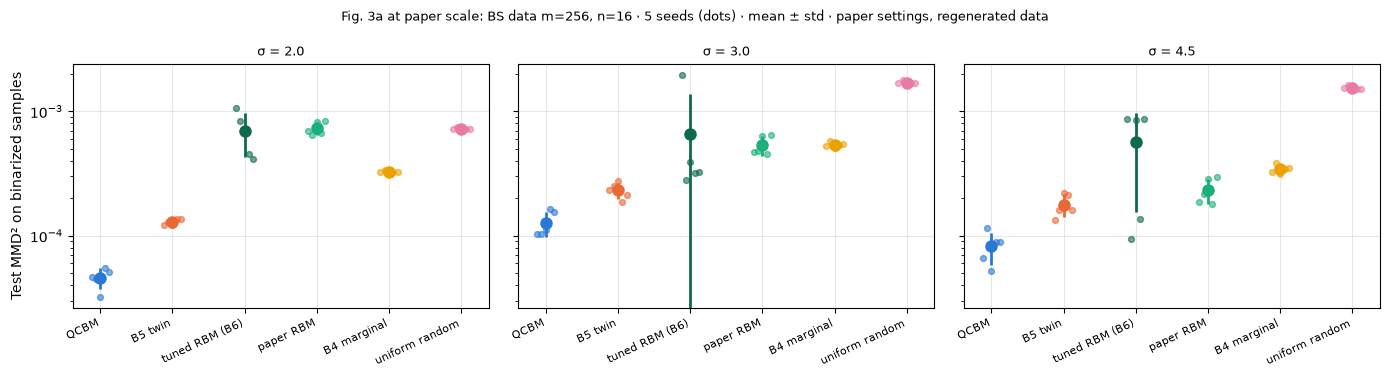

metric         gaussian_mmd_binarized                     gaussian_mmd_raw  \
sigma                             2.0       3.0       4.5              2.0   
model                                                                        
QCBM                        4.607e-05 1.271e-04 8.216e-05        3.005e-05   
B5 twin                     1.296e-04 2.323e-04 1.782e-04        2.220e-04   
tuned RBM (B6)              6.970e-04 6.537e-04 5.617e-04        4.562e-03   
paper RBM                   7.314e-04 5.363e-04 2.332e-04        5.065e-03   
B4 marginal                 3.259e-04 5.375e-04 3.435e-04        8.570e-04   
uniform random              7.219e-04 1.694e-03 1.536e-03        1.112e-03   

metric                             walsh_mmd                      
sigma                3.0       4.5       2.0       3.0       4.5  
model                                                             
QCBM           1.185e-04 9.089e-05 3.671e-05 1.043e-04 6.974e-05  
B5 twin        4.818e-04 3.353e-04 3.097e-04 4.499e-04 3.023e-04  
tuned RBM (B6) 6.677e-03 4.087e-03 1.915e-04 1.940e-04 2.115e-04  
paper RBM      6.643e-03 3.249e-03 8.874e-05 1.024e-04 1.018e-04  
B4 marginal    1.743e-03 1.016e-03 1.302e-03 1.882e-03 1.085e-03  
uniform random 2.827e-03 2.341e-03 1.672e-03 2.923e-03 2.116e-03

In [13]:
systems = comparison["c4"]["systems"]
NAMES = {"QCBM (Phase 3, JAX + Perceval)": "QCBM", "B5 distinguishable twin": "B5 twin",
         "B6 tuned RBM": "tuned RBM (B6)", "paper RBM": "paper RBM", "B4 marginal": "B4 marginal",
         "uniform random": "uniform random"}
rows = []
for key, name in NAMES.items():
    for sigma, entry in systems[key].items():
        for metric in ("gaussian_mmd_binarized", "walsh_mmd", "gaussian_mmd_raw"):
            for seed, value in enumerate(entry[metric]["values"]):
                rows.append({"model": name, "sigma": sigma, "metric": metric, "seed": seed, "value": value})
fig3a = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, sigma in zip(axes, ["2.0", "3.0", "4.5"]):
    strip_plot(ax, fig3a[fig3a.sigma == sigma], list(NAMES.values()), "gaussian_mmd_binarized", f"σ = {sigma}")
axes[0].set_ylabel("Test MMD² on binarized samples")
fig.suptitle("Fig. 3a at paper scale: BS data m=256, n=16 · 5 seeds (dots) · mean ± std · paper settings, regenerated data", fontsize=9)
plt.tight_layout(); plt.show()

fig3a.pivot_table(index="model", columns=["metric", "sigma"], values="value", aggfunc="mean").loc[list(NAMES.values())]

**Observation (Fig. 3a).** On raw counts and on binarized samples the QCBM has the lowest mean at
every σ: 35–170× below the RBMs on raw counts, 2.8–16× on binarized samples. On parity features
the margin is small, and at σ = 3 the paper RBM's mean is marginally *lower* (1.02e-4 vs 1.04e-4,
within noise).

**Inference.** The paper's qualitative statement ("the QCBM clearly outperforms RBM and random")
holds on the paper's metric, but the *size* of the margin is largely a representation effect: a
binary RBM cannot emit counts, which costs it 7–14× on raw counts.

**Claim impact.** C4 trend reproduced; its strength depends on the metric (examined in §8–§9).

Now the other figures, as rankings from the stored sweep tables (paper's own estimator
`test_mmd_estimator` for QCBM variants; sample-based for baselines):

In [14]:
def candidates(sweep):
    out = {}
    for key, entry in tables[sweep]["candidates"].items():
        out[json.loads(key)["label"]] = entry["metrics"]
    return out

def mean_of(metrics, name):
    return metrics[name]["mean"] if name in metrics else np.nan

fig3b = candidates("fig3b_sushi")
fig3b["butterfly_reference"] = candidates("fig3b_sushi_butterfly_reference_attempt2")["butterfly_reference"]
pd.DataFrame({label: {"QCBM test MMD² (paper estimator)": mean_of(m, "test_mmd_estimator"),
                      "QCBM sample MMD² (walsh)": mean_of(m, "model.walsh_mmd"),
                      "unitarity error": mean_of(m, "unitarity_error"),
                      "paper RBM (walsh)": mean_of(m, "rbm.walsh_mmd"),
                      "B4 marginal (walsh)": mean_of(m, "marginal.walsh_mmd")}
              for label, m in fig3b.items()}).T.sort_values("QCBM test MMD² (paper estimator)")

,QCBM test MMD² (paper estimator),QCBM sample MMD² (walsh),unitarity error,paper RBM (walsh),B4 marginal (walsh)
butterfly_reference,5.852e-04,NaN,2.282e+00,3.489e-04,3.389e-04
haar,6.202e-04,6.851e-04,1.110e-15,3.489e-04,3.389e-04
butterfly_corrected,6.492e-04,6.792e-04,2.620e-15,3.489e-04,3.389e-04
clements,1.225e-02,1.355e-02,3.109e-15,3.489e-04,3.389e-04
mzi3,1.647e-02,1.779e-02,2.320e-14,3.489e-04,3.389e-04


**Fig. 3b (C5, sushi, m = 100, n = 10).** Haar and the corrected butterfly (≈7e-4) are ~20× better
than Clements and 3-MZI: **ranking reproduced**. The original butterfly has a unitarity error of
order 1 after training, so it has no sample-based score (not deployable); its low
"paper estimator" value is computed from a non-unitary matrix and does not describe any physical
interferometer. Note that the paper's RBM
and the first-order B4 sampler both score *lower* than the best QCBM here.

In [15]:
init_rows = []
for sweep, ansatz in [("fig3c_movies_haar", "Haar"), ("fig3d_movies_butterfly_corrected", "butterfly (corrected)"),
                      ("fig3d_movies_butterfly_reference", "butterfly (original, not unitary)")]:
    for label, m in candidates(sweep).items():
        init, sigma = label.rsplit("_sigma", 1)
        init_rows.append({"ansatz": ansatz, "init": init, "sigma": sigma,
                          "mean": m["test_mmd_estimator"]["mean"], "std": m["test_mmd_estimator"]["std"]})
inits = pd.DataFrame(init_rows)
spread = inits.groupby(["ansatz", "sigma"]).agg(best=("mean", "min"), worst=("mean", "max"), largest_seed_std=("std", "max"))
spread["worst / best"] = spread.worst / spread.best
spread

best     worst  largest_seed_std  \
ansatz                            sigma                                         
Haar                              1.5   1.262e-03 1.317e-03         5.939e-05   
                                  2.5   1.530e-03 1.547e-03         8.814e-05   
                                  3.5   7.540e-04 7.838e-04         4.671e-05   
butterfly (corrected)             1.5   1.360e-03 1.406e-03         8.842e-05   
                                  2.5   1.560e-03 1.596e-03         1.440e-04   
                                  3.5   7.716e-04 8.627e-04         1.251e-04   
butterfly (original, not unitary) 1.5   1.107e-03 1.197e-03         2.665e-04   
                                  2.5   1.525e-03 2.518e-03         1.076e-03   
                                  3.5   9.448e-04 2.088e-03         9.348e-04   

                                         worst / best  
ansatz                            sigma                
Haar                              1.5       1.044e+00  
                                  2.5       1.011e+00  
                                  3.5       1.040e+00  
butterfly (corrected)             1.5       1.034e+00  
                                  2.5       1.024e+00  
                                  3.5       1.118e+00  
butterfly (original, not unitary) 1.5       1.081e+00  
                                  2.5       1.651e+00  
                                  3.5       2.210e+00

**Fig. 3c/3d (C6, movies).** For unitary ansätze (Haar, corrected butterfly) the worst and best
initializations differ by little relative to seed spread: **"no large gaps" reproduced**. The large
seed spread the paper attributes to the butterfly appears only for the *original, non-unitary*
mesh. (Haar ran on one L4 machine and the butterflies on another; training was shown to be bitwise
identical across these machines, see `LOG.md`.)

In [16]:
block = []
for sweep in ("fig4a_pairwise_sushi", "fig4b_mushroom"):
    for label, m in candidates(sweep).items():
        block.append({"dataset": sweep.split("_", 1)[1], "init": label,
                      "test MMD² (paper estimator)": m["test_mmd_estimator"]["mean"],
                      "std": m["test_mmd_estimator"]["std"]})
pd.DataFrame(block).sort_values(["dataset", "test MMD² (paper estimator)"]).set_index(["dataset", "init"])

test MMD² (paper estimator)       std
dataset        init                                                   
mushroom       block_uniform                       9.687e-03 4.438e-04
               identity                            1.201e-02 1.581e-03
               weak_unbiased                       1.464e-02 2.477e-03
               data_dependent                      1.517e-02 1.846e-03
               random                              1.567e-02 2.394e-03
pairwise_sushi pairwise_uniform                    9.815e-03 8.574e-04
               identity                            1.644e-02 4.801e-03
               data_dependent                      2.416e-02 4.323e-03
               random                              2.780e-02 5.888e-03
               weak_unbiased                       3.526e-02 1.030e-02

**Fig. 4 (C7).** The block-structured initializations (pairwise / block uniform) are best on both
toy datasets: **reproduced** (smaller margin on mushroom). The paper itself notes these datasets
are built to match the initialization.

Fig. 3e/3f (kernels) are examined as controls in §9, because the interesting part there is the
comparison with the RBM.

## 8. Fair baseline comparison

The paper's comparison for C4 is the RBM. Is it a fair opponent? Dimension by dimension
(the word *matched* is used only where it is true):

| Dimension | QCBM | paper RBM | tuned RBM (B6) | B5 twin | B4 marginal |
|---|---|---|---|---|---|
| Information / inputs | train split, raw counts | train split, raw counts fed to Bernoulli units (mismatched representation) | train split, **binarized** (its own representation) | same as QCBM (matched) | train mode frequencies only |
| Output space | counts, weight n | bits, any weight | bits, any weight | counts, weight n | bits, weight n |
| Parameters | 131 072 | 16 704 (8× fewer) | 16 704–131 840 by selection; **matched** at 512 hidden | 131 072 (matched) | 256 |
| Training data | 5000 | 5000 | 4000 for selection, 5000 for refit | 5000 | 5000 |
| Optimization | Adam, ≤ 2000 steps, stopping rule (~428 steps) | 2000 epochs CD | 2000 epochs per candidate | same as QCBM (matched) | none |
| Tuning budget | 1 configuration (code defaults) | 1 configuration | 18 candidates (favours the baseline) | 1 | none |
| Compute / wall time per seed | 92 s (L4 GPU, JAX) | 88 s (CPU) | 2947 s whole protocol (CPU) | 12 s (GPU) | ~0 |
| Evaluation protocol | same test split, 2000 samples, same estimators and K operators (matched for all) | same | same | same | same |

Wall times are on the same machine but different implementations (GPU JAX vs CPU sklearn), so
they describe this code, not the algorithms.

Decisions on the **primary metric** with the frozen rule ($|\Delta| > 2\,$SE):

In [17]:
decisions = pd.DataFrame(comparison["c4"]["comparisons"])
primary_decisions = decisions[(decisions.method == "QCBM (Phase 3, JAX + Perceval)") & decisions.primary]
table = primary_decisions.pivot(index="baseline", columns="sigma", values="verdict")
table.loc[["paper RBM", "B6 tuned RBM", "B5 distinguishable twin", "B4 marginal", "uniform random"]]

sigma,2.0,3.0,4.5
baseline,,,
paper RBM,method better,method better,method better
B6 tuned RBM,method better,not separated,method better
B5 distinguishable twin,method better,method better,method better
B4 marginal,method better,method better,method better
uniform random,method better,method better,method better


In [18]:
ratio = primary_decisions.pivot(index="baseline", columns="sigma", values="ratio_baseline_over_method")
print("baseline mean / QCBM mean on the primary metric:")
print(ratio.round(1).loc[["paper RBM", "B6 tuned RBM", "B5 distinguishable twin", "B4 marginal", "uniform random"]].to_string())
print("\nC4 outcome by the frozen rule:", comparison["c4"]["outcome_by_frozen_rule"])
b6_s3 = np.array(systems["B6 tuned RBM"]["3.0"]["gaussian_mmd_binarized"]["values"])
q_s3 = np.array(systems["QCBM (Phase 3, JAX + Perceval)"]["3.0"]["gaussian_mmd_binarized"]["values"])
print("σ=3 per seed — tuned RBM:", np.round(b6_s3, 6), "| QCBM:", np.round(q_s3, 6))

baseline mean / QCBM mean on the primary metric:
sigma                         2.0       3.0       4.5
baseline                                             
paper RBM               1.590e+01 4.200e+00 2.800e+00
B6 tuned RBM            1.510e+01 5.100e+00 6.800e+00
B5 distinguishable twin 2.800e+00 1.800e+00 2.200e+00
B4 marginal             7.100e+00 4.200e+00 4.200e+00
uniform random          1.570e+01 1.330e+01 1.870e+01

C4 outcome by the frozen rule: PARTIALLY_SUPPORTED
σ=3 per seed — tuned RBM: [0.001959 0.000279 0.000388 0.00032  0.000323] | QCBM: [0.000103 0.000103 0.000111 0.000163 0.000155]


**Observation.** The QCBM beats every classical baseline on the primary metric at σ = 2 and 4.5.
At σ = 3 it is **not separated** from the tuned RBM: every tuned-RBM seed is above every QCBM seed,
but one RBM seed is very poor (2.0e-3), so the standard error is large and the frozen rule calls it
a tie. The QCBM beats the classically samplable twin B5 by only 1.8–2.8×.

**Inference.** With a representation-matched, parameter-matched, tuned RBM the QCBM still leads on
binarized samples at two of three bandwidths. But most of its margin over the RBMs is also obtained
by B5, which uses the same circuit with distinguishable photons and is easy to sample classically.

**Remaining uncertainty.** The tuned RBM shows a large validation-to-test gap (§10), so a better
tuning protocol might narrow the gap further. The data come from a boson sampler, a model class the
QCBM contains, which favours it by construction.

**Claim impact.** **C4 partially supported**: the direction holds, the margin is metric-dependent,
and the lead over the classically samplable twin is 1.8–2.8×, not orders of magnitude; that is an
upper bound on what interference contributes (§11). No quantum advantage is claimed.

## 9. Controls and ablations

Three controls, each targeting a specific alternative explanation.

**9a — Interference control (B5).** *Alternative explanation:* "the QCBM wins because its
architecture or training fits the data, not because of bosonic interference." B5 keeps everything
except indistinguishability, but it is *trained separately*, so it can also end at a different
optimum. Result (§8): B5 already beats both RBMs and B4 on the primary metric; the QCBM's remaining
lead is 1.8–2.8×. The m = 16 noise study (§11) shows the QCBM's own circuit, sampled with fully
distinguishable photons, still beating B5, so part of that lead is a better-trained circuit, not
interference. *Impact:* 1.8–2.8× is an upper bound on the interference contribution at m = 256.

**9b — Representation control (metric choice).** *Alternative explanation:* "the margin over the RBM
is an artefact of scoring binary models on counts." The table below shows the QCBM / paper-RBM
ratio under each representation.

In [19]:
rep = (fig3a[fig3a.model.isin(["QCBM", "paper RBM", "tuned RBM (B6)"])]
       .groupby(["metric", "sigma", "model"]).value.mean().unstack("model"))
rep["paper RBM / QCBM"] = rep["paper RBM"] / rep["QCBM"]
rep["tuned RBM / QCBM"] = rep["tuned RBM (B6)"] / rep["QCBM"]
rep[["QCBM", "paper RBM", "tuned RBM (B6)", "paper RBM / QCBM", "tuned RBM / QCBM"]]

model                             QCBM  paper RBM  tuned RBM (B6)  \
metric                 sigma                                        
gaussian_mmd_binarized 2.0   4.607e-05  7.314e-04       6.970e-04   
                       3.0   1.271e-04  5.363e-04       6.537e-04   
                       4.5   8.216e-05  2.332e-04       5.617e-04   
gaussian_mmd_raw       2.0   3.005e-05  5.065e-03       4.562e-03   
                       3.0   1.185e-04  6.643e-03       6.677e-03   
                       4.5   9.089e-05  3.249e-03       4.087e-03   
walsh_mmd              2.0   3.671e-05  8.874e-05       1.915e-04   
                       3.0   1.043e-04  1.024e-04       1.940e-04   
                       4.5   6.974e-05  1.018e-04       2.115e-04   

model                         paper RBM / QCBM  tuned RBM / QCBM  
metric                 sigma                                      
gaussian_mmd_binarized 2.0           1.588e+01         1.513e+01  
                       3.0           4.219e+00         5.143e+00  
                       4.5           2.839e+00         6.837e+00  
gaussian_mmd_raw       2.0           1.686e+02         1.518e+02  
                       3.0           5.607e+01         5.635e+01  
                       4.5           3.574e+01         4.497e+01  
walsh_mmd              2.0           2.417e+00         5.215e+00  
                       3.0           9.822e-01         1.860e+00  
                       4.5           1.460e+00         3.033e+00

*Observation:* ratios of 35–170× on raw counts shrink to 2.8–16× on binarized samples and to about
1–5× on parity features (with ties at σ = 3). *Impact:* the headline size of the Fig. 3a gap is
mostly a representation effect.

**9c — Same-kernel control for Fig. 3e (C8).** The paper says that with the degree-2 polynomial
kernel the QCBM "slightly overtakes" the RBM on movies. *Alternative explanation:* the two models
were scored with different kernels.

In [20]:
c8 = comparison["c8_part2"]["kernels"]
pd.DataFrame({k: {"QCBM": v["qcbm"]["mean"], "paper RBM": v["paper_rbm"]["mean"], "B4 marginal": v["b4_marginal"]["mean"],
                  "decision QCBM vs RBM": v["qcbm_vs_rbm"]["verdict"]} for k, v in c8.items()}).T

,QCBM,paper RBM,B4 marginal,decision QCBM vs RBM
polynomial2,7.947e-04,4.352e-04,6.038e-04,baseline better
gaussian2.5,1.605e-03,7.486e-04,1.299e-03,baseline better
gaussian3.5,8.098e-04,4.486e-04,6.356e-04,baseline better


In [21]:
fig3e = candidates("fig3e_movies")
qcbm_poly_estimator = fig3e["polynomial2"]["test_mmd_estimator"]["mean"]
rbm_gauss25 = fig3e["gaussian2.5"]["rbm.gaussian_mmd_raw"]["mean"]
rbm_poly = fig3e["polynomial2"]["rbm.walsh_mmd"]["mean"]
print(f"QCBM, polynomial kernel, paper estimator : {qcbm_poly_estimator:.3e}")
print(f"RBM,  polynomial kernel (same kernel)    : {rbm_poly:.3e}   -> RBM better")
print(f"RBM,  Gaussian σ=2.5 (different kernel)  : {rbm_gauss25:.3e}   -> 'QCBM slightly better' only across kernels")

QCBM, polynomial kernel, paper estimator : 7.148e-04
RBM,  polynomial kernel (same kernel)    : 4.352e-04   -> RBM better
RBM,  Gaussian σ=2.5 (different kernel)  : 7.718e-04   -> 'QCBM slightly better' only across kernels


*Observation:* under every kernel, with the same estimator for both, the RBM is better than the
QCBM, and so is the first-order B4 sampler. The paper's statement is reproduced only when the QCBM's
polynomial-kernel score is compared with the RBM's Gaussian-kernel score, which is the only RBM
score the released code produces. *Impact:* **C8 part 2 unsupported** like-for-like (likely a
cross-kernel comparison; cannot be confirmed without the authors' plotting code). On bioinformatics
(Fig. 3f) the QCBM beats the uniform random model under all six kernels (`results/results_tables.md`).

**9d — Butterfly control.** Covered in §4c and §7: the paper's butterfly sensitivity disappears
with a unitary butterfly.

## 10. Robustness and uncertainty

**Seed variability.** Every stochastic comparison above uses 5 seeds and shows them individually.

**Selection optimism of the tuned RBM.** Each seed chose its RBM on a validation split; compare
that validation score with the test score of the refit model.

In [22]:
b6 = systems["B6 tuned RBM"]
pd.DataFrame({sigma: {"validation (selected)": np.mean(b6[sigma]["selected_validation_mmd"]["values"]),
                      "test (refit)": b6[sigma]["gaussian_mmd_binarized"]["mean"],
                      "test / validation": b6[sigma]["gaussian_mmd_binarized"]["mean"] / np.mean(b6[sigma]["selected_validation_mmd"]["values"]),
                      "selected sizes (params)": "/".join(str(int(v)) for v in b6[sigma]["selected_parameters"]["values"])}
              for sigma in ["2.0", "3.0", "4.5"]}).T

,validation (selected),test (refit),test / validation,selected sizes (params)
2.0,1.185e-04,6.970e-04,5.883e+00,131840/131840/131840/131840/131840
3.0,9.624e-05,6.537e-04,6.792e+00,131840/16704/16704/16704/16704
4.5,5.004e-05,5.617e-04,1.122e+01,131840/16704/16704/131840/131840


**Observation.** The selected RBMs look 6–11× better on validation than on test. Likely causes are
picking the minimum of 18 noisy candidates (winner's curse) and refit instability (persistent CD at
lr 1e-2 with 512 hidden units). This was not diagnosed further, so the tuned RBM may be
underperforming what a more careful protocol would achieve; this is the main reason the σ = 3 tie
should not be read as "the QCBM wins" either.

**Other uncertainty sources (documented in `LOG.md`):**
- Perceval's `Clifford2017Backend` ignores `pcvl.random_seed`; QCBM sample metrics move by
  0.3–0.7% between reruns. Training and the paper's estimator are bitwise reproducible across
  machines and code versions.
- Paper values are plots only, not digitized: metric agreement is not assessable.
- Movies and bioinformatics data are rebuilt and unverified; the BS data is a new instance.
- Fig. 2 (|K|, |Z| oscillations) is a single seed: step-to-step loss std 7.5e-6 (2000) vs
  3.7e-6 (5000), consistent with C3 but preliminary.

## 11. Photonic assessment: the MerLin adaptation

The model is already linear optics, so MerLin can express it natively (status
`MERLIN_IMPLEMENTATION`). This is an **adaptation**, kept separate from the reproduction above.
Three parts:
- **M1** — the paper's estimator in PyTorch on MerLin-compiled interferometers;
- **M2** — deployment with the MerLin engine's seeded GPU Clifford sampler;
- **M3** — exact SLOS evaluation of small trained models under partial distinguishability and loss,
  with photon-number-resolving (PNR) vs threshold detectors.

Live check: the native MerLin mesh is unitary, is the identity at internal phases π (not 0), and
MerLin's exact SLOS distribution equals our permanent-based one.

In [23]:
import torch
from photonic_MMD_generative.lib import qcbm_merlin

mesh = qcbm_merlin.MerlinInterferometer(8, "merlin_mesh", "cpu")
identity_params = mesh.initial_parameters({"strategy": "identity", "perturbation": 0.0}, jax.random.PRNGKey(0))
U_id = mesh.unitary(identity_params)
U_zero = mesh.unitary(torch.zeros(mesh.num_parameters, dtype=torch.float64))
print("mesh parameters:", mesh.num_parameters)
print("max | |U| - I | at internal phases pi :", float((U_id.abs() - torch.eye(8)).abs().max()))
print("max | |U| - I | at all phases 0       :", float((U_zero.abs() - torch.eye(8)).abs().max()))
ours = exact.output_distribution(U_small, INPUT_MODES_SMALL)
merlin = exact.merlin_output_distribution(U_small, INPUT_MODES_SMALL)
print("max |p_permanent - p_MerLin SLOS| (m=6, n=2):", max(abs(ours[s] - merlin[s]) for s in ours))

mesh parameters: 56
max | |U| - I | at internal phases pi : 2.4492935982947064e-16
max | |U| - I | at all phases 0       : 1.0
max |p_permanent - p_MerLin SLOS| (m=6, n=2): 2.7755575615628914e-17


In [24]:
backend_rows = []
for fig in ("fig3a", "fig3b"):
    for row in json.loads((RESULTS / f"phase4_{fig}_backend_comparison.json").read_text()):
        backend_rows.append({"figure": fig, "MerLin": row["merlin"], "metric": row["metric"],
                             "MerLin mean": row["merlin_mean"], "JAX mean": row["jax_mean"],
                             "Δ": row["delta"], "preserved (|Δ| ≤ 2 SE)": row["preserved"]})
pd.DataFrame(backend_rows).query("metric in ['test_mmd_estimator', 'model.walsh_mmd', 'seconds_per_step']")

,figure,MerLin,metric,MerLin mean,JAX mean,Δ,preserved (|Δ| ≤ 2 SE)
0,fig3a,qcbm_merlin_sigma3.0,test_mmd_estimator,1.079e-04,1.079e-04,2.021e-17,True
1,fig3a,qcbm_merlin_sigma3.0,model.walsh_mmd,1.077e-04,1.043e-04,3.354e-06,True
6,fig3a,qcbm_merlin_sigma3.0,seconds_per_step,3.325e-01,2.152e-01,1.173e-01,None
7,fig3a,b5_merlin_sigma3.0,test_mmd_estimator,4.907e-04,4.907e-04,4.326e-17,True
8,fig3a,b5_merlin_sigma3.0,model.walsh_mmd,4.499e-04,4.499e-04,1.084e-19,True
13,fig3a,b5_merlin_sigma3.0,seconds_per_step,3.076e-02,2.655e-02,4.214e-03,None
14,fig3b,haar_merlin,test_mmd_estimator,6.202e-04,6.202e-04,-4.613e-16,True
15,fig3b,haar_merlin,model.walsh_mmd,7.032e-04,6.851e-04,1.801e-05,True
20,fig3b,haar_merlin,seconds_per_step,1.985e-01,1.482e-01,5.034e-02,None
21,fig3b,merlin_mesh,test_mmd_estimator,5.694e-02,1.225e-02,4.468e-02,False


**M1/M2 observation.** On Fig. 3a (σ = 3) and Fig. 3b the MerLin backend reproduces the JAX
training to ~1e-16 (same losses, stopping step and trained unitary); sample-based metrics agree
within 2 SE (the MerLin sampler is seeded, Perceval's is not). The native MerLin mesh started near
identity trains far worse than Haar (5.9e-2 vs 7.0e-4 on sushi), as the paper found for meshes.

**M3 — imperfect sources and detectors** (exact MerLin SLOS, m = 16, n = 4, 5 seeds, BS data,
postselected on n detections). Label: *characterization*: the tuned RBM did not run under these
conditions.

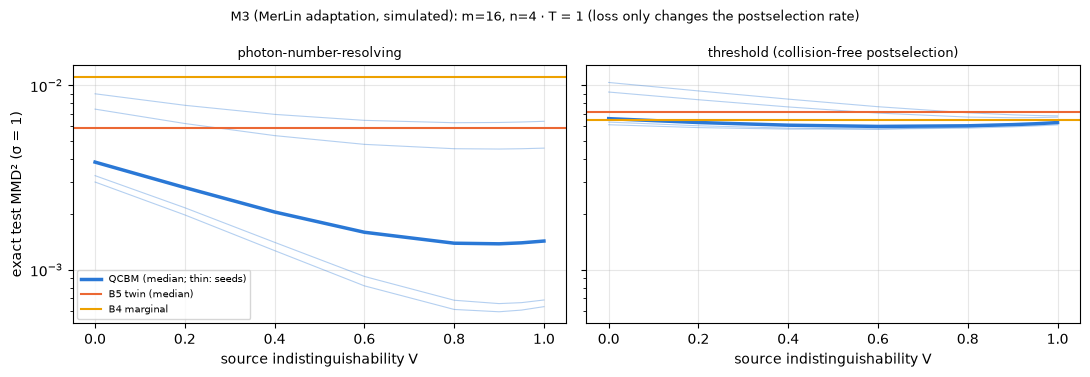

In [25]:
noise = json.loads((RESULTS / "phase4_noise_study.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, detector in zip(axes, ("pnr", "threshold")):
    rows_n = sorted((r for r in noise["grid"] if r["size"] == "m16" and r["model"] == "qcbm"
                     and r["transmittance"] == 1.0 and r["detector"] == detector), key=lambda r: r["indistinguishability"])
    V = [r["indistinguishability"] for r in rows_n]
    per_seed = np.array([r["exact_mmd"]["values"] for r in rows_n])
    for curve in per_seed.T:
        ax.plot(V, curve, color=COLORS["QCBM"], alpha=0.35, linewidth=0.8)
    ax.plot(V, np.median(per_seed, axis=1), color=COLORS["QCBM"], linewidth=2.5, label="QCBM (median; thin: seeds)")
    b5_native = next(r for r in noise["grid"] if r["size"] == "m16" and r["model"] == "b5" and r["indistinguishability"] == 0.0
                     and r["transmittance"] == 1.0 and r["detector"] == detector)
    ax.axhline(b5_native["exact_mmd"]["median"], color=COLORS["B5 twin"], label="B5 twin (median)")
    marginal = next(r for r in noise["references"] if r["size"] == "m16" and r["reference"] == "marginal" and r["detector"] == detector)
    ax.axhline(marginal["mean"], color=COLORS["B4 marginal"], label="B4 marginal")
    ax.set_yscale("log"); ax.set_xlabel("source indistinguishability V"); ax.grid(alpha=0.3)
    ax.set_title("photon-number-resolving" if detector == "pnr" else "threshold (collision-free postselection)", fontsize=9)
axes[0].set_ylabel("exact test MMD² (σ = 1)"); axes[0].legend(fontsize=7)
fig.suptitle("M3 (MerLin adaptation, simulated): m=16, n=4 · T = 1 (loss only changes the postselection rate)", fontsize=9)
plt.tight_layout(); plt.show()

**Observation.** With PNR detectors the QCBM's median MMD² is flat down to V ≈ 0.8 (1.4e-3) and
stays below its distinguishable twin at every V, even fully distinguishable photons (V = 0: 3.8e-3
vs 5.9e-3). With threshold detectors (only collision-free events kept, 47%)
its edge over the first-order sampler disappears. Uniform loss followed by postselection on n
photons leaves the distribution unchanged; only the event rate drops. Seeds are bimodal for the reason
shown in §6: some trainings end in a poor local optimum (not a stopping-rule artefact).

**Photonic verdict.** The method maps natively onto linear optics and MerLin reproduces it exactly.
Lowering V degrades the QCBM (median 1.4e-3 → 3.8e-3), but even at V = 0 its circuit beats the
separately trained twin, so the comparison with B5 mixes interference with optimization quality.
Photon-number-resolving detection is required: with threshold detection the edge over a
first-order sampler disappears. All of this is simulation; nothing ran on hardware.
Hardware-aware settings: `README.md`, *Hardware-Aware Settings*.

## 12. Conclusions

Five different statements, kept apart:

| Statement | Status | Evidence |
|---|---|---|
| The software executes end to end | yes | §6 (live), sweep ledgers in `LOG.md` |
| The method solves the task (learns held-out data) | yes on BS data at paper scale; seed-dependent at m = 12; weaker than first-order baselines on real data | §6, §7, §9c |
| The paper's metric values reproduce | not assessable (plots not digitized) | §7 |
| The paper's explanation survives controls | partly: the QCBM beats its distinguishable twin on BS data, but part of that is optimization, not interference; the margin over the RBMs is mostly representation; the butterfly and Fig. 3e statements do not survive | §8, §9, §11 |
| The method beats a fair baseline | on BS data at σ 2 and 4.5, tie at σ 3; not on movies | §8, §9c |

**1. What reproduced.**
- C1: Walsh/permanent identity and unbiased estimator (§4).
- C2: efficient training at paper scale (0.21 s/step at m = 256 on an L4; §5, `README.md`).
- C5: ansatz ranking Haar ≈ corrected butterfly ≪ Clements, 3-MZI (§7).
- C6 (part): no large gaps between initializations for unitary ansätze (§7).
- C7: block initializations best on block toy data (§7).
- C4 direction: the QCBM has the lowest MMD² on BS data on every metric (§7).

**2. What did not reproduce.**
- C8 part 2: on movies the RBM beats the QCBM under every kernel when both use the same estimator (§9c).
- C6 (part): butterfly sensitivity to initialization exists only for the non-unitary original mesh (§4c, §7).

**3. What remains unresolved.**
- C4 at σ = 3 against the tuned RBM (tie by variability; tuned RBM shows selection optimism, §8, §10).
- Trainability: at m = 12, 2 of 5 QCBM seeds end in a poor local optimum of the training objective
  even without early stopping (§6); at m = 256 the five seeds are tight (§7). How often this
  happens across sizes was not mapped.
- Whether the paper's Fig. 3e statement came from a cross-kernel comparison (§9c).
- Exact numerical agreement with the paper (plots not digitized).

**4. What was not attempted.**
- C10 (bandwidth warm start), C11 (dequantization), QPU execution, digitizing the paper's figures,
  the tuned RBM on movies or under M3 noise.

**5. Reproduction verdict.** *Partially reproduced.* The training scheme is correct and efficient,
and most qualitative findings hold, though training is seed-sensitive at small m (§6). The comparative claims are weaker than stated: on boson-sampling
data the QCBM's lead depends on the metric and is mostly matched by a classically samplable twin
(remaining lead 1.8–2.8×, an upper bound on the interference contribution), and on real datasets
simple first-order baselines beat it (§7–§9, §11).

**6. Photonic verdict.** *MerLin implementation, simulated.* MerLin reproduces training exactly and
provides a seeded sampler. With PNR detectors the trained QCBM stays below its separately trained
distinguishable twin at every indistinguishability V, which shows part of its edge is a better
circuit rather than interference; with threshold detectors the edge over a first-order sampler
disappears (§11). No quantum advantage is
claimed.